# **Lab 8 - Edge Detection: Assignment**

**Objective:** Apply and compare edge detection methods (Sobel, Prewitt, Canny) using Python and OpenCV, and investigate how the Canny thresholds affect the detected edges.

**Image used:** `my_image.jpg` (a new colour image of a house, tree and garden, different from the `kid1.jpg` used in the reference notebook). To use another image, just change `imgFile` below.

## Selected image

The image is a colour scene (house, tree, garden) that I drew with code, so it is different from the one in the original notebook. If `my_image.jpg` is not in the folder, the cell below creates it automatically. To use your own photo instead, put it in the folder and change `imgFile` in the next cell.

In [1]:
import cv2
import numpy as np
import os

def make_image(path):
    """Draws the garden/house scene used in this assignment and saves it to `path`."""
    rng=np.random.default_rng(7)
    H,W=480,640
    img=np.zeros((H,W,3),np.float32)
    # sky gradient (BGR)
    for y in range(H):
        t=y/H; img[y,:]=(235-60*t, 190-40*t, 110+30*t)
    # sun with glow
    yy,xx=np.mgrid[0:H,0:W]
    d=np.sqrt((xx-520)**2+(yy-90)**2)
    img+= (np.exp(-(d/70)**2)[...,None]*np.array([40,120,180]))
    cv2.circle(img,(520,90),38,(120,230,255),-1)
    # clouds
    for cx,cy in [(120,80),(300,60),(380,130)]:
        for dx,dy,r in [(0,0,28),(30,5,24),(-30,8,22),(15,-14,22)]:
            cv2.circle(img,(cx+dx,cy+dy),r,(250,250,250),-1)
    img=cv2.GaussianBlur(img,(0,0),1.2)
    # distant hills
    pts=np.array([[0,300]]+[[x,300-40*np.sin(x/90)-25*np.sin(x/37)] for x in range(0,W+1,8)]+[[W,H],[0,H]],np.int32)
    cv2.fillPoly(img,[pts],(90,140,70))
    # ground
    cv2.rectangle(img,(0,340),(W,H),(60,150,60),-1)
    # grass texture
    for _ in range(6000):
        x=rng.integers(0,W); y=rng.integers(340,H); l=rng.integers(4,10)
        cv2.line(img,(int(x),int(y)),(int(x+rng.integers(-2,3)),int(y-l)),(int(40+rng.integers(0,40)),int(120+rng.integers(0,60)),int(30+rng.integers(0,40))),1)
    # path
    cv2.fillPoly(img,[np.array([[300,H],[380,H],[345,345],[335,345]])],(150,175,200))
    # house
    cv2.rectangle(img,(110,230),(300,350),(170,200,235),-1)            # walls
    cv2.fillPoly(img,[np.array([[95,235],[205,150],[315,235]])],(40,60,150))  # roof
    cv2.rectangle(img,(190,285),(225,350),(30,70,110),-1)               # door
    cv2.circle(img,(218,320),2,(60,200,230),-1)
    for (x0,y0) in [(130,260),(245,260)]:
        cv2.rectangle(img,(x0,y0),(x0+40,y0+40),(200,160,90),-1)
        cv2.rectangle(img,(x0,y0),(x0+40,y0+40),(255,255,255),2)
        cv2.line(img,(x0+20,y0),(x0+20,y0+40),(255,255,255),2); cv2.line(img,(x0,y0+20),(x0+40,y0+20),(255,255,255),2)
    cv2.rectangle(img,(255,170),(280,215),(60,70,160),-1)               # chimney
    # brick lines
    for y in range(235,350,12): cv2.line(img,(110,y),(300,y),(150,180,215),1)
    # tree
    cv2.rectangle(img,(470,260),(495,370),(40,70,100),-1)
    for _ in range(900):
        a=rng.uniform(0,2*np.pi); r=rng.uniform(0,70)
        cx=int(483+r*np.cos(a)); cy=int(220+0.85*r*np.sin(a))
        cv2.circle(img,(cx,cy),int(rng.integers(5,10)),(int(30+rng.integers(0,40)),int(110+rng.integers(0,90)),int(30+rng.integers(0,50))),-1)
    for _ in range(25):
        cv2.circle(img,(int(483+rng.uniform(-60,60)),int(220+rng.uniform(-50,50))),5,(40,40,220),-1)  # red fruits
    # flowers
    for _ in range(45):
        x=rng.integers(20,W-20); y=rng.integers(370,H-10); c=[(255,255,255),(60,60,230),(40,220,250),(230,100,200)][rng.integers(0,4)]
        cv2.circle(img,(int(x),int(y)),3,c,-1)
    # fence
    for x in range(20,100,14):
        cv2.rectangle(img,(x,330),(x+8,375),(220,235,245),-1)
    cv2.line(img,(15,345),(110,345),(220,235,245),3); cv2.line(img,(15,362),(110,362),(220,235,245),3)
    img=np.clip(img+rng.normal(0,3,img.shape),0,255).astype(np.uint8)
    cv2.imwrite(path, img, [cv2.IMWRITE_JPEG_QUALITY, 92])

# Create the image automatically if it is not already in the folder
if not os.path.exists('my_image.jpg'):
    make_image('my_image.jpg')
    print('my_image.jpg was not found -> created it.')

my_image.jpg was not found -> created it.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'my_image.jpg'      # <-- selected image (not the one in the original notebook)

img  = cv2.imread(imgFile)                     # colour (BGR)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # grayscale
print("Image:", imgFile, "| size:", gray.shape)

# Helper: scale float edge maps to 0..255 (np.uint8() on values > 255 would wrap around)
def to_uint8(x):
    return cv2.normalize(np.absolute(x), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

Image: my_image.jpg | size: (480, 640)


# Task 1: Apply Edge Detection Methods

## 1. Sobel Edge Detector

Gaussian blur to reduce noise, then the 3x3 Sobel derivatives in x and y, combined as `sqrt(Gx² + Gy²)`.

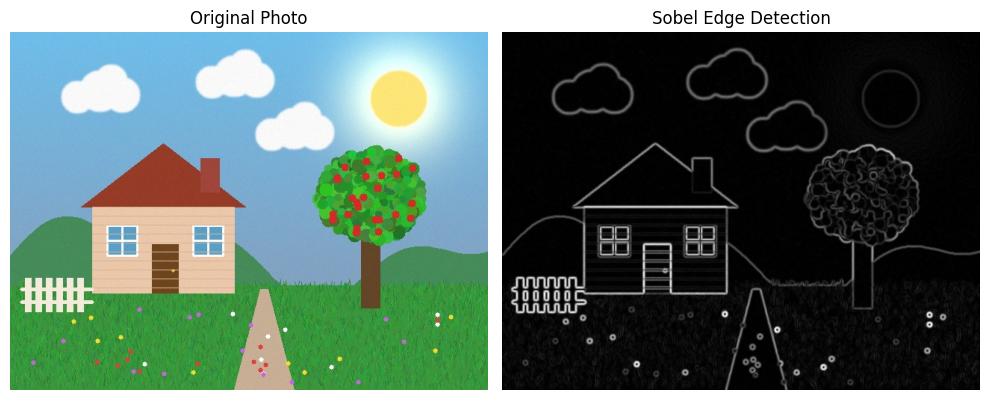

In [3]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = to_uint8(sobel_combined)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Prewitt Edge Detector

Similar to Sobel but with equal weights in the kernel.

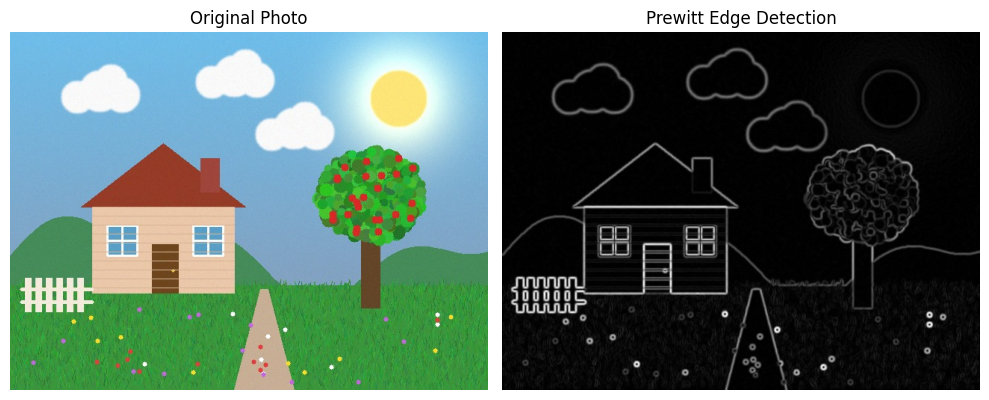

In [4]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = to_uint8(prewitt_combined)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

## 3. Canny Edge Detector

`cv2.Canny(image, low_threshold, high_threshold)` with thresholds (100, 200).

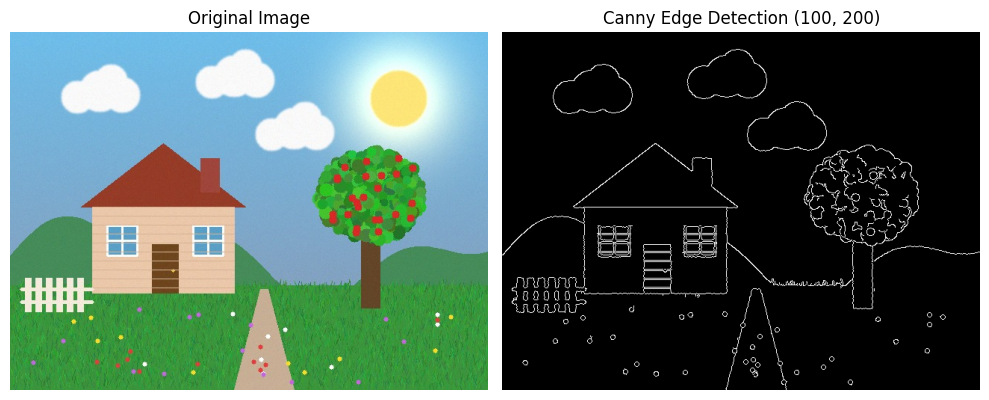

In [5]:
canny_edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

## Display: original image and the three edge maps

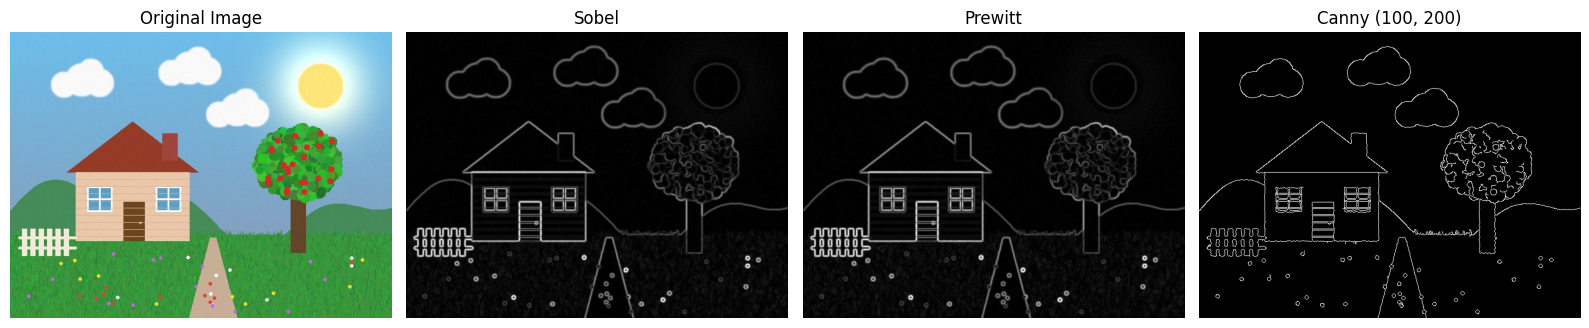

In [6]:
plt.figure(figsize=(16, 4.5))
plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(1, 4, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel')
plt.subplot(1, 4, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt')
plt.subplot(1, 4, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny (100, 200)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

**Comparison:** Sobel and Prewitt are first-derivative operators and produce *gradient-magnitude* maps: thick, grey-level edges whose brightness shows edge strength (Sobel gives slightly smoother results because of the centre weight 2). Canny produces a *binary*, thin (1-pixel) and connected edge map thanks to non-maximum suppression and hysteresis thresholding, so it is the cleanest of the three.

# Task 2: Investigate the Effect of Canny Thresholds

Low= 30, High= 90  ->  edge pixels = 28,911  (9.41% of the image)
Low= 50, High=150  ->  edge pixels = 13,070  (4.25% of the image)
Low=100, High=200  ->  edge pixels =  8,023  (2.61% of the image)


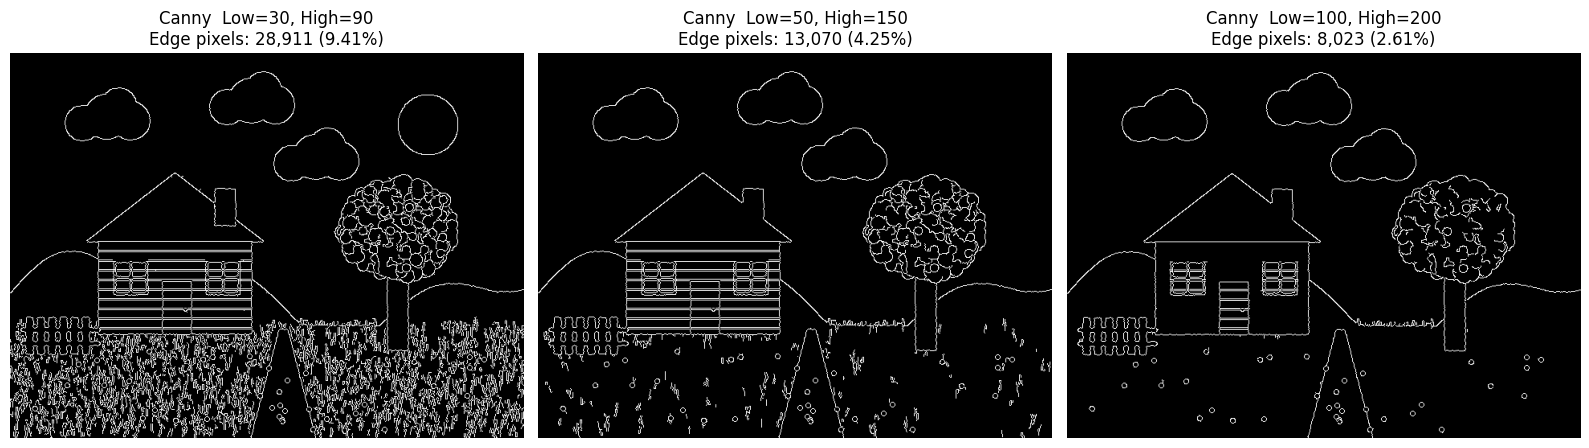

In [7]:
thresholds = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(16, 5.5))
for i, (low, high) in enumerate(thresholds):
    edges = cv2.Canny(gray, low, high)
    n = int(np.count_nonzero(edges))
    pct = 100 * n / edges.size
    plt.subplot(1, 3, i + 1), plt.imshow(edges, cmap='gray')
    plt.title(f'Canny  Low={low}, High={high}\nEdge pixels: {n:,} ({pct:.2f}%)'), plt.axis('off')
    print(f"Low={low:>3}, High={high:>3}  ->  edge pixels = {n:>6,}  ({pct:.2f}% of the image)")
plt.tight_layout()
plt.show()

### Explanation: effect of the Canny thresholds

Canny uses **hysteresis thresholding**: a pixel whose gradient is above the *high* threshold is a strong edge (kept); a pixel below the *low* threshold is discarded; pixels in between are kept **only if they are connected to a strong edge**.

| Low | High | Edge pixels | % of image |
|---|---|---|---|
| 30 | 90 | 28,911 | 9.41 % |
| 50 | 150 | 13,070 | 4.25 % |
| 100 | 200 | 8,023 | 2.61 % |

* **Low thresholds (30, 90):** the most edges are detected (about 3.6x more than with 100/200). Even the faint edge of the sun's glow appears, and the brick lines, window frames and every leaf/fruit of the tree are visible. The drawback is that weak gradients and noise are also turned into edges: the grass at the bottom becomes a dense, cluttered mess of small edges.
* **Medium thresholds (50, 150):** a balanced result. The house (roof, bricks, windows, door), the fence, the tree, the clouds, the path and the hills are all clear, while most of the grass texture is removed and the faint sun disappears.
* **High thresholds (100, 200):** the cleanest map; only strong, high-contrast structures survive (house outline, windows, fence, tree, clouds, hills and path). Low-contrast details such as the brick lines and the door details are lost or broken, and the grass is almost completely gone.

**Conclusion:** increasing the thresholds *reduces* the number of detected edges and removes weak details and noise; decreasing them *increases* the number of edges and the visible detail, at the cost of more noise. A high:low ratio of about 2:1 to 3:1 is a good choice, and the best pair depends on how much detail the application needs.